In [3]:

!pip -q install pandas numpy matplotlib seaborn scipy openpyxl python-pptx

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from google.colab import files
from IPython.display import display

OUTPUT_DIR = "/content/ApexPlanet_Task4_Output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Upload your ApexPlanet Excel sales dataset.")
uploaded = files.upload()

excel_files = [
    name for name in uploaded
    if name.lower().endswith((".xlsx", ".xls"))
]

if not excel_files:
    raise ValueError("Please upload an Excel dataset.")

excel_file = excel_files[0]
df_raw = pd.read_excel(excel_file, sheet_name="Sales_Dataset")

print("Dataset uploaded successfully.")
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])
display(df_raw.head())


Upload your ApexPlanet Excel sales dataset.


Saving ApexPlanet_DataAnalytics_Dataset (4).xlsx to ApexPlanet_DataAnalytics_Dataset (4) (1).xlsx
Dataset uploaded successfully.
Rows: 1000
Columns: 12


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [5]:

required_columns = [
    "Order_ID", "Order_Date", "Customer_ID", "Customer_Name",
    "Age", "Gender", "City", "Product", "Category",
    "Quantity", "Unit_Price", "Total_Sales"
]

missing_columns = [
    col for col in required_columns if col not in df_raw.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

raw = df_raw.copy()

# Initial quality assessment
exact_duplicates = int(raw.duplicated().sum())
missing_counts = raw.isna().sum()

duplicate_order_ids = int(
    raw.loc[raw["Order_ID"].duplicated(keep=False), "Order_ID"].nunique()
)

dates_original = pd.to_datetime(raw["Order_Date"], errors="coerce")
invalid_dates = int(dates_original.isna().sum())

for col in ["Quantity", "Unit_Price", "Total_Sales", "Age"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

calculated_sales = raw["Quantity"] * raw["Unit_Price"]
valid_sales_rows = raw["Quantity"].notna() & raw["Unit_Price"].notna()

sales_mismatches = int(
    (
        ~np.isclose(
            raw.loc[valid_sales_rows, "Total_Sales"],
            calculated_sales.loc[valid_sales_rows],
            rtol=1e-4,
            atol=0.01
        )
    ).sum()
)

# Clean exact duplicate rows and text columns
data = raw.drop_duplicates().copy()

text_columns = [
    "Order_ID", "Customer_ID", "Customer_Name",
    "Gender", "City", "Product", "Category"
]

for col in text_columns:
    data[col] = data[col].astype("string").str.strip()

data["Order_Date"] = pd.to_datetime(
    data["Order_Date"], errors="coerce"
)

for col in ["Quantity", "Unit_Price", "Total_Sales", "Age"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Correct sales values from quantity and unit price when both exist
valid = data["Quantity"].notna() & data["Unit_Price"].notna()
data.loc[valid, "Total_Sales"] = (
    data.loc[valid, "Quantity"] * data.loc[valid, "Unit_Price"]
)

# Handle missing values
if data["Age"].notna().any():
    data["Age"] = data["Age"].fillna(data["Age"].median())

if data["City"].notna().any():
    data["City"] = data["City"].fillna(data["City"].mode().iloc[0])
else:
    data["City"] = data["City"].fillna("Unknown")

for col in ["Gender", "Customer_Name", "Product", "Category"]:
    data[col] = data[col].replace("", pd.NA).fillna("Unknown")

# Exclude rows missing essential analysis fields
data = data.dropna(
    subset=[
        "Order_ID", "Order_Date", "Customer_ID",
        "Quantity", "Unit_Price", "Total_Sales"
    ]
).copy()

data = data[data["Total_Sales"] >= 0].copy()

data["Year"] = data["Order_Date"].dt.year
data["Month"] = data["Order_Date"].dt.month
data["Year_Month"] = data["Order_Date"].dt.to_period("M").astype(str)

quality_summary = pd.DataFrame({
    "Quality Check": [
        "Original row count",
        "Original column count",
        "Exact duplicate rows",
        "Missing Age values",
        "Missing City values",
        "Distinct repeated Order_IDs",
        "Invalid dates",
        "Sales calculation mismatches",
        "Rows after preparation",
        "Unique customers after preparation"
    ],
    "Result": [
        len(df_raw),
        len(df_raw.columns),
        exact_duplicates,
        int(missing_counts["Age"]),
        int(missing_counts["City"]),
        duplicate_order_ids,
        invalid_dates,
        sales_mismatches,
        len(data),
        data["Customer_ID"].nunique()
    ]
})

display(quality_summary)
print("Data preparation completed.")


,Quality Check,Result
0,Original row count,1000
1,Original column count,12
2,Exact duplicate rows,0
3,Missing Age values,20
4,Missing City values,13
5,Distinct repeated Order_IDs,1
6,Invalid dates,0
7,Sales calculation mismatches,0
8,Rows after preparation,1000
9,Unique customers after preparation,947


Data preparation completed.


In [6]:

# Core KPIs
total_revenue = data["Total_Sales"].sum()
unique_orders = data["Order_ID"].nunique()
total_customers = data["Customer_ID"].nunique()
average_order_value = (
    total_revenue / unique_orders if unique_orders else 0
)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Unique Orders",
        "Unique Customers",
        "Average Order Value"
    ],
    "Value": [
        total_revenue,
        unique_orders,
        total_customers,
        average_order_value
    ]
})

# Revenue summaries
monthly_summary = (
    data.groupby("Year_Month", as_index=False)
    .agg(
        Total_Revenue=("Total_Sales", "sum"),
        Unique_Orders=("Order_ID", "nunique")
    )
    .sort_values("Year_Month")
)

category_summary = (
    data.groupby("Category", as_index=False)
    .agg(
        Total_Revenue=("Total_Sales", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
)

city_summary = (
    data.groupby("City", as_index=False)
    .agg(
        Total_Revenue=("Total_Sales", "sum"),
        Unique_Orders=("Order_ID", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Customer RFM metrics
reference_date = data["Order_Date"].max() + pd.Timedelta(days=1)

rfm = (
    data.groupby("Customer_ID")
    .agg(
        Last_Purchase_Date=("Order_Date", "max"),
        Frequency=("Order_ID", "size"),
        Monetary=("Total_Sales", "sum"),
        Customer_Name=("Customer_Name", "first"),
        City=("City", "first")
    )
    .reset_index()
)

rfm["Recency_Days"] = (
    reference_date - rfm["Last_Purchase_Date"]
).dt.days

def quintile_score(series, higher_is_better=True):
    scores = np.ceil(
        series.rank(method="first", pct=True) * 5
    ).clip(1, 5).astype(int)

    return scores if higher_is_better else 6 - scores

rfm["R_Score"] = quintile_score(
    rfm["Recency_Days"], higher_is_better=False
)
rfm["F_Score"] = quintile_score(
    rfm["Frequency"], higher_is_better=True
)
rfm["M_Score"] = quintile_score(
    rfm["Monetary"], higher_is_better=True
)

def assign_segment(row):
    r, f, m = row["R_Score"], row["F_Score"], row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 3:
        return "Loyal Customers"
    elif r >= 4 and f <= 2:
        return "Recent Customers"
    elif r <= 2 and f >= 3:
        return "At Risk"
    elif r <= 2 and f <= 2:
        return "Needs Attention"
    else:
        return "Potential Loyalists"

rfm["Customer_Segment"] = rfm.apply(assign_segment, axis=1)

segment_summary = (
    rfm.groupby("Customer_Segment", as_index=False)
    .agg(
        Customer_Count=("Customer_ID", "nunique"),
        Total_Revenue=("Monetary", "sum"),
        Average_Customer_Revenue=("Monetary", "mean"),
        Average_Recency_Days=("Recency_Days", "mean"),
        Average_Frequency=("Frequency", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

segment_summary["Customer_Percentage"] = (
    segment_summary["Customer_Count"]
    / segment_summary["Customer_Count"].sum() * 100
)

print("CORE KPIs")
display(kpi_summary)

print("REVENUE BY CATEGORY")
display(category_summary)

print("CUSTOMER SEGMENTS")
display(segment_summary)


CORE KPIs


,KPI,Value
0,Total Revenue,1.393994e+08
1,Unique Orders,9.920000e+02
2,Unique Customers,9.470000e+02
3,Average Order Value,1.405236e+05


REVENUE BY CATEGORY


,Category,Total_Revenue,Quantity_Sold
1,Electronics,50778581.70,1978
0,Education,25031689.40,977
4,Grocery,22231711.28,826
3,Furniture,21521561.48,855
2,Fashion,19835895.79,799


CUSTOMER SEGMENTS


,Customer_Segment,Customer_Count,Total_Revenue,Average_Customer_Revenue,Average_Recency_Days,Average_Frequency,Customer_Percentage
0,At Risk,219,34023395.98,155357.972511,291.287671,1.027397,23.125660
2,Loyal Customers,273,31427982.27,115120.814176,116.391941,1.058608,28.827878
1,Champions,77,21807947.46,283220.096883,60.168831,1.402597,8.130940
5,Recent Customers,141,20971458.51,148733.748298,67.127660,1.000000,14.889124
3,Needs Attention,160,19214786.50,120092.415625,287.162500,1.000000,16.895459
4,Potential Loyalists,77,11953868.93,155245.051039,177.831169,1.000000,8.130940


In [7]:

# Identify customers whose gender is consistent across all their records
gender_counts = data.groupby("Customer_ID")["Gender"].nunique()

consistent_customer_ids = gender_counts[
    gender_counts == 1
].index

gender_spending = (
    data[data["Customer_ID"].isin(consistent_customer_ids)]
    .groupby(["Customer_ID", "Gender"], as_index=False)
    .agg(Customer_Total_Sales=("Total_Sales", "sum"))
)

female = gender_spending.loc[
    gender_spending["Gender"] == "Female",
    "Customer_Total_Sales"
].dropna()

male = gender_spending.loc[
    gender_spending["Gender"] == "Male",
    "Customer_Total_Sales"
].dropna()

if len(female) < 2 or len(male) < 2:
    raise ValueError("Not enough customers in both groups for testing.")

# Hypothesis:
# H0: Female and male customers have equal mean total spending.
# H1: Their mean total spending differs.

alpha = 0.05

test_result = stats.ttest_ind(
    female,
    male,
    equal_var=False
)

mean_female = female.mean()
mean_male = male.mean()
difference = mean_female - mean_male

# Welch confidence interval for the difference in means
var_f = female.var(ddof=1)
var_m = male.var(ddof=1)
n_f = len(female)
n_m = len(male)

standard_error = np.sqrt(var_f / n_f + var_m / n_m)

welch_df = (
    (var_f / n_f + var_m / n_m) ** 2
    /
    (
        (var_f / n_f) ** 2 / (n_f - 1)
        + (var_m / n_m) ** 2 / (n_m - 1)
    )
)

critical_t = stats.t.ppf(0.975, welch_df)

ci_low = difference - critical_t * standard_error
ci_high = difference + critical_t * standard_error

pooled_sd = np.sqrt(
    (
        (n_f - 1) * var_f
        + (n_m - 1) * var_m
    ) / (n_f + n_m - 2)
)

cohens_d = difference / pooled_sd if pooled_sd else np.nan

if test_result.pvalue < alpha:
    conclusion = (
        "Reject H0: evidence of a statistically significant difference "
        "in mean customer spending between the two groups."
    )
else:
    conclusion = (
        "Fail to reject H0: insufficient evidence of a statistically "
        "significant difference in mean customer spending."
    )

hypothesis_summary = pd.DataFrame({
    "Metric": [
        "Null hypothesis",
        "Alternative hypothesis",
        "Statistical test",
        "Significance level",
        "Female customer count",
        "Male customer count",
        "Female mean customer spending",
        "Male mean customer spending",
        "Mean difference (Female - Male)",
        "t statistic",
        "Degrees of freedom (Welch)",
        "p-value",
        "95% CI lower bound",
        "95% CI upper bound",
        "Cohen's d",
        "Conclusion"
    ],
    "Result": [
        "The mean spending is equal between groups",
        "The mean spending differs between groups",
        "Welch's independent-samples t-test",
        alpha,
        n_f,
        n_m,
        mean_female,
        mean_male,
        difference,
        test_result.statistic,
        welch_df,
        test_result.pvalue,
        ci_low,
        ci_high,
        cohens_d,
        conclusion
    ]
})

display(hypothesis_summary)


,Metric,Result
0,Null hypothesis,The mean spending is equal between groups
1,Alternative hypothesis,The mean spending differs between groups
2,Statistical test,Welch's independent-samples t-test
3,Significance level,0.05
4,Female customer count,445
5,Male customer count,468
6,Female mean customer spending,138779.511236
7,Male mean customer spending,143641.791709
8,Mean difference (Female - Male),-4862.280473
9,t statistic,-0.620937


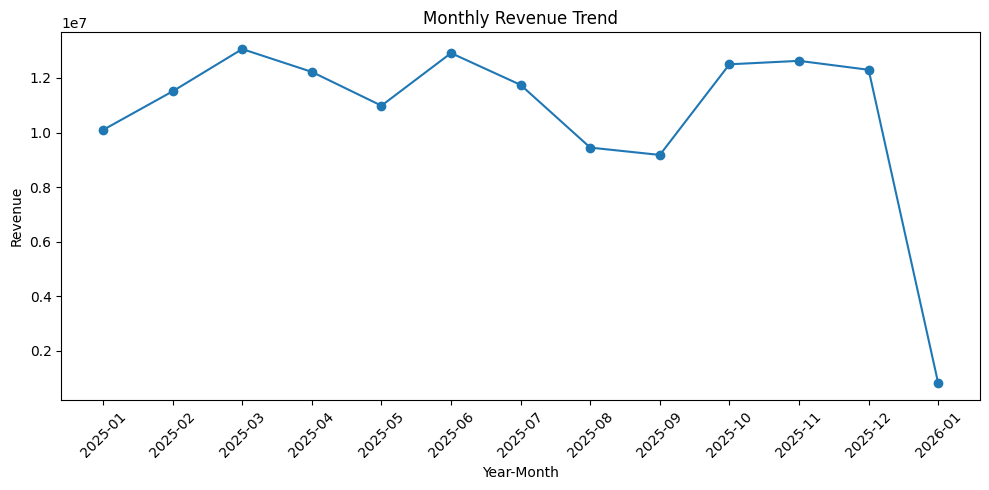

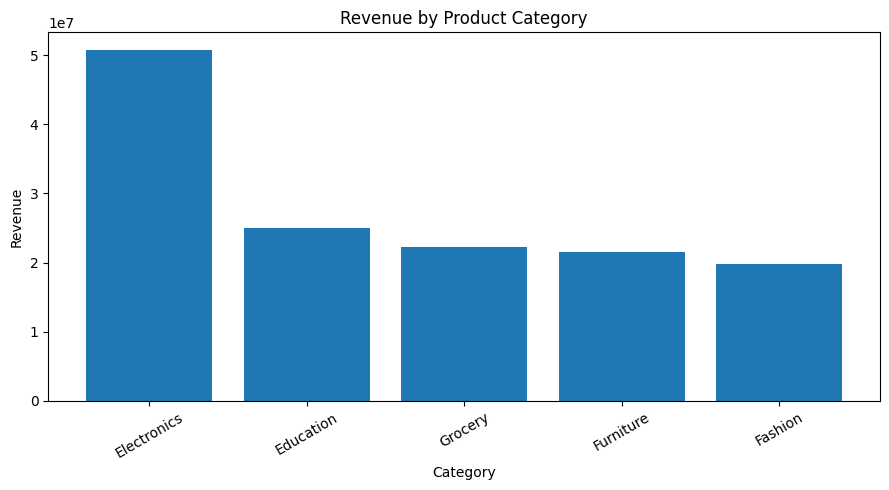

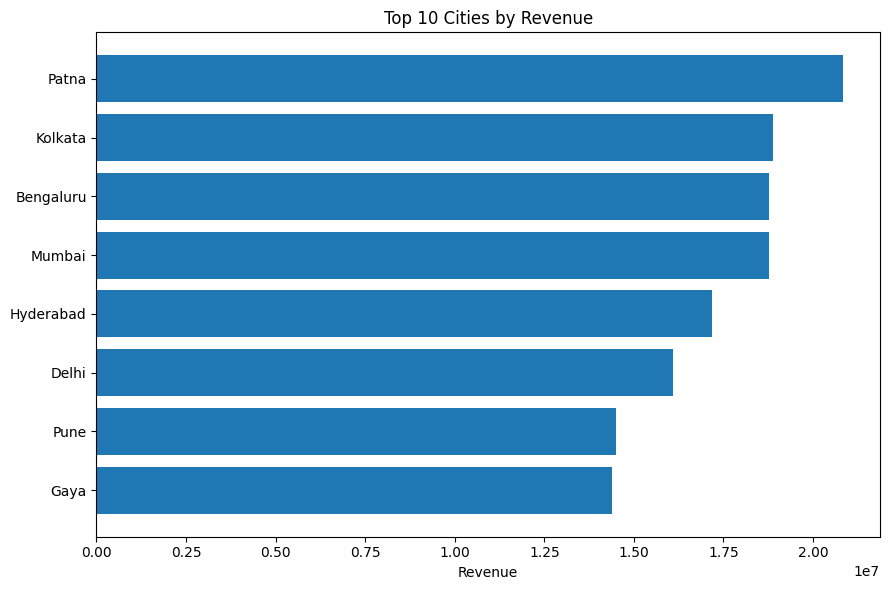

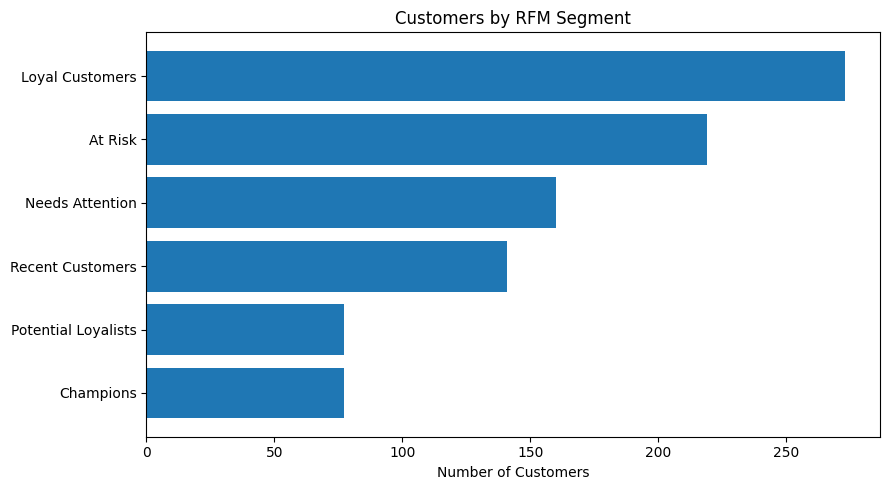

All charts saved.


In [8]:

# 1. Monthly revenue
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_summary["Year_Month"],
    monthly_summary["Total_Revenue"],
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Year-Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/Task4_Monthly_Revenue.png",
    dpi=200
)
plt.show()

# 2. Revenue by category
plt.figure(figsize=(9, 5))
plt.bar(
    category_summary["Category"],
    category_summary["Total_Revenue"]
)
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/Task4_Revenue_by_Category.png",
    dpi=200
)
plt.show()

# 3. Revenue by city
top_cities = city_summary.head(10).sort_values("Total_Revenue")

plt.figure(figsize=(9, 6))
plt.barh(
    top_cities["City"],
    top_cities["Total_Revenue"]
)
plt.title("Top 10 Cities by Revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/Task4_Revenue_by_City.png",
    dpi=200
)
plt.show()

# 4. Customer segment sizes
segments_by_count = segment_summary.sort_values("Customer_Count")

plt.figure(figsize=(9, 5))
plt.barh(
    segments_by_count["Customer_Segment"],
    segments_by_count["Customer_Count"]
)
plt.title("Customers by RFM Segment")
plt.xlabel("Number of Customers")
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/Task4_Customers_by_Segment.png",
    dpi=200
)
plt.show()

print("All charts saved.")


In [9]:

top_category = category_summary.iloc[0]
top_city = city_summary.iloc[0]
top_month = monthly_summary.loc[
    monthly_summary["Total_Revenue"].idxmax()
]
top_segment = segment_summary.iloc[0]

findings = [
    f"The dataset contains {len(data):,} usable transaction rows.",
    f"Total recorded sales revenue is {total_revenue:,.2f}.",
    f"There are {unique_orders:,} distinct order IDs.",
    f"There are {total_customers:,} distinct customers.",
    (
        f"{top_category['Category']} is the highest-revenue category, "
        f"with revenue of {top_category['Total_Revenue']:,.2f}."
    ),
    (
        f"{top_city['City']} is the highest-revenue city, "
        f"with revenue of {top_city['Total_Revenue']:,.2f}."
    ),
    (
        f"{top_month['Year_Month']} is the highest-revenue month in the "
        f"available data, with revenue of {top_month['Total_Revenue']:,.2f}."
    ),
    (
        f"{top_segment['Customer_Segment']} is the customer segment with "
        f"the highest total RFM-segment revenue, "
        f"{top_segment['Total_Revenue']:,.2f}."
    ),
    conclusion,
    (
        "The gender spending comparison is observational and does not "
        "establish a causal relationship."
    )
]

print("TASK 4 BUSINESS FINDINGS")
for i, finding in enumerate(findings, start=1):
    print(f"{i}. {finding}")

with open(
    f"{OUTPUT_DIR}/ApexPlanet_Task4_Findings.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("TASK 4: DATA STORYTELLING & STATISTICAL VALIDATION\n\n")
    f.write("\n".join(f"{i}. {v}" for i, v in enumerate(findings, 1)))


TASK 4 BUSINESS FINDINGS
1. The dataset contains 1,000 usable transaction rows.
2. Total recorded sales revenue is 139,399,439.65.
3. There are 992 distinct order IDs.
4. There are 947 distinct customers.
5. Electronics is the highest-revenue category, with revenue of 50,778,581.70.
6. Patna is the highest-revenue city, with revenue of 20,826,584.43.
7. 2025-03 is the highest-revenue month in the available data, with revenue of 13,059,899.94.
8. At Risk is the customer segment with the highest total RFM-segment revenue, 34,023,395.98.
9. Fail to reject H0: insufficient evidence of a statistically significant difference in mean customer spending.
10. The gender spending comparison is observational and does not establish a causal relationship.


In [10]:

with pd.ExcelWriter(
    f"{OUTPUT_DIR}/ApexPlanet_Task4_Statistical_Report.xlsx",
    engine="openpyxl"
) as writer:
    quality_summary.to_excel(
        writer, sheet_name="Data_Quality", index=False
    )
    kpi_summary.to_excel(
        writer, sheet_name="Core_KPIs", index=False
    )
    monthly_summary.to_excel(
        writer, sheet_name="Monthly_Sales", index=False
    )
    category_summary.to_excel(
        writer, sheet_name="Category_Summary", index=False
    )
    city_summary.to_excel(
        writer, sheet_name="City_Summary", index=False
    )
    segment_summary.to_excel(
        writer, sheet_name="RFM_Segments", index=False
    )
    hypothesis_summary.to_excel(
        writer, sheet_name="Hypothesis_Test", index=False
    )
    pd.DataFrame({"Business Finding": findings}).to_excel(
        writer, sheet_name="Story_Findings", index=False
    )

print("Excel statistical report created.")


Excel statistical report created.


In [11]:

from pptx import Presentation
from pptx.util import Inches, Pt

prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)

def add_bullet_slide(title, bullets):
    slide = prs.slides.add_slide(prs.slide_layouts[1])
    slide.shapes.title.text = title

    text_frame = slide.placeholders[1].text_frame
    text_frame.clear()

    for i, bullet in enumerate(bullets):
        paragraph = (
            text_frame.paragraphs[0]
            if i == 0
            else text_frame.add_paragraph()
        )
        paragraph.text = bullet
        paragraph.level = 0
        paragraph.font.size = Pt(19)

    return slide

def add_chart_slide(title, image_path, bullets):
    slide = prs.slides.add_slide(prs.slide_layouts[6])

    title_box = slide.shapes.add_textbox(
        Inches(0.5), Inches(0.25), Inches(12), Inches(0.7)
    )
    title_box.text_frame.text = title
    title_box.text_frame.paragraphs[0].font.size = Pt(28)
    title_box.text_frame.paragraphs[0].font.bold = True

    slide.shapes.add_picture(
        image_path,
        Inches(0.45), Inches(1.25),
        width=Inches(6.5)
    )

    box = slide.shapes.add_textbox(
        Inches(7.1), Inches(1.35),
        Inches(5.6), Inches(5.4)
    )

    tf = box.text_frame
    tf.word_wrap = True
    tf.clear()

    for i, bullet in enumerate(bullets):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.text = bullet
        p.font.size = Pt(17)
        p.space_after = Pt(12)

    return slide

# Slide 1: Title
slide = prs.slides.add_slide(prs.slide_layouts[0])
slide.shapes.title.text = (
    "Data Storytelling & Statistical Validation"
)
slide.placeholders[1].text = (
    "ApexPlanet Software Pvt. Ltd.\n"
    "60-Day Data Analytics Internship\n"
    "Task 4 | Prepared by Bhavana V"
)

# Slide 2: Executive summary
add_bullet_slide(
    "Executive Summary",
    [
        f"Total sales revenue: {total_revenue:,.2f}",
        f"Distinct order IDs: {unique_orders:,}",
        f"Distinct customers: {total_customers:,}",
        f"Highest-revenue category: {top_category['Category']}",
        f"Highest-revenue city: {top_city['City']}",
        "Analysis combines sales trends, RFM segmentation, and statistical validation."
    ]
)

# Slide 3: Data quality
add_bullet_slide(
    "Data Quality & Preparation",
    [
        f"Original dataset: {len(df_raw):,} rows and {len(df_raw.columns)} columns.",
        f"Exact duplicate rows detected: {exact_duplicates}.",
        f"Missing age values: {int(missing_counts['Age'])}.",
        f"Missing city values: {int(missing_counts['City'])}.",
        f"Distinct repeated order IDs: {duplicate_order_ids}.",
        "Missing values were handled, dates standardized, and sales recalculated from quantity and unit price where available.",
        "Repeated order IDs were not automatically deleted."
    ]
)

# Slide 4: Category performance
add_chart_slide(
    "Sales Performance by Category",
    f"{OUTPUT_DIR}/Task4_Revenue_by_Category.png",
    [
        f"Top category: {top_category['Category']}.",
        f"Recorded category revenue: {top_category['Total_Revenue']:,.2f}.",
        "Use category performance to guide further product-level investigation."
    ]
)

# Slide 5: Monthly revenue
add_chart_slide(
    "Monthly Revenue Trend",
    f"{OUTPUT_DIR}/Task4_Monthly_Revenue.png",
    [
        f"Highest-revenue month: {top_month['Year_Month']}.",
        f"Revenue in that month: {top_month['Total_Revenue']:,.2f}.",
        "Compare monthly fluctuations before planning promotions or inventory."
    ]
)

# Slide 6: Customer segmentation
add_chart_slide(
    "RFM Customer Segmentation",
    f"{OUTPUT_DIR}/Task4_Customers_by_Segment.png",
    [
        f"Highest-revenue segment: {top_segment['Customer_Segment']}.",
        f"Segment revenue: {top_segment['Total_Revenue']:,.2f}.",
        "RFM scores use recency, transaction-record frequency, and monetary value.",
        "Consider testing suitable retention strategies for at-risk segments."
    ]
)

# Slide 7: Hypothesis test
add_bullet_slide(
    "Statistical Hypothesis Testing",
    [
        "H0: Mean customer spending is equal for female and male customers.",
        "H1: Mean customer spending differs between the two groups.",
        "Test: Welch's independent-samples t-test.",
        f"Female mean spending: {mean_female:,.2f} (n={n_f}).",
        f"Male mean spending: {mean_male:,.2f} (n={n_m}).",
        f"p-value: {test_result.pvalue:.4f}.",
        f"95% CI for mean difference: [{ci_low:,.2f}, {ci_high:,.2f}].",
        conclusion
    ]
)

# Slide 8: Recommendations and limitations
add_bullet_slide(
    "Recommendations & Conclusion",
    [
        f"Investigate the drivers of revenue in {top_category['Category']}.",
        f"Review sales performance and customer mix in {top_city['City']}.",
        "Use RFM segments to guide customer engagement experiments.",
        "Continue monitoring monthly revenue and customer spending.",
        "The hypothesis test does not establish a statistically significant gender-group difference at the 5% level.",
        "The analysis is observational; results do not establish causation."
    ]
)

pptx_path = (
    f"{OUTPUT_DIR}/ApexPlanet_Task4_Final_Presentation.pptx"
)
prs.save(pptx_path)

print("PowerPoint created:", pptx_path)


PowerPoint created: /content/ApexPlanet_Task4_Output/ApexPlanet_Task4_Final_Presentation.pptx


In [12]:

import shutil
from google.colab import files

zip_base = "/content/ApexPlanet_Task4_Deliverables"

shutil.make_archive(
    zip_base,
    "zip",
    OUTPUT_DIR
)

print("Your Task 4 deliverables are ready.")
files.download(zip_base + ".zip")


Your Task 4 deliverables are ready.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>